In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from scipy.stats import kruskal
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import balanced_accuracy_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.neighbors import NearestCentroid

output_dir = Path("images")
output_dir.mkdir(exist_ok=True)

In [136]:
file_path = 'C:/MASTER/AC - Aprendizagem computacional/Project/DataSet/diabetes_risk.csv'

df = pd.read_csv(file_path)
df

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low


In [137]:
df = df.drop(columns=['patient_id'], errors='ignore')

print("Shape:", df.shape)
df.columns

Shape: (15000, 18)


Index(['age', 'gender', 'city', 'bmi', 'family_history_diabetes',
       'physical_activity_level', 'diet_type', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket',
       'diabetes_risk'],
      dtype='object')

In [138]:
df.describe()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


In [139]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())



Missing values:
age                            0
gender                         0
city                           0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
income_bracket               463
diabetes_risk                  0
dtype: int64

Number of duplicate rows: 0


In [140]:
print("\nUnique values in each column:")
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


Unique values in each column:

 age
[47 53 41 57 58 42 44 51 38 22 26 46 49 37 40 63 45 39 55 48]

 gender
['Female' 'Male' 'Other']

 city
['Mumbai' 'Thane' 'Bengaluru' 'Hyderabad' 'Delhi' 'Kolkata' 'Ahmedabad'
 'Pune' 'Chennai' 'Kanpur' 'Bhopal' 'Visakhapatnam' 'Patna' 'Jaipur'
 'Surat' 'Nagpur' 'Indore' 'Lucknow']

 bmi
[26.5 20.5 31.3 22.8 16.7 22.  22.5 19.5 20.3 24.1 21.5 23.3 19.3 15.
 21.4 19.6 21.7 26.8 20.4 18.2]

 family_history_diabetes
['Yes' 'No']

 physical_activity_level
['Sedentary' 'Moderate' 'Active']

 diet_type
['Vegetarian' 'Non-Vegetarian' 'Pescatarian' 'Vegan']

 smoking_status
['Never' 'Current' nan 'Former']

 alcohol_consumption
['Never' 'Regular' 'Occasional' nan]

 hours_sleep_per_night
[ 9.   7.   6.5  6.9  6.   4.8  6.2 10.   8.9  8.   7.6  7.9  6.3  5.3
  8.1  6.6  7.7  8.4  8.5  7.5]

 stress_level
[ 8  6  7  5 10  2  4  9  1  3]

 fasting_blood_sugar
[178 152 168 155 188 148 190 270 186 139 158 160  94 119 118 115 167 228
 162 143]

 hba1c_level
[7.3 

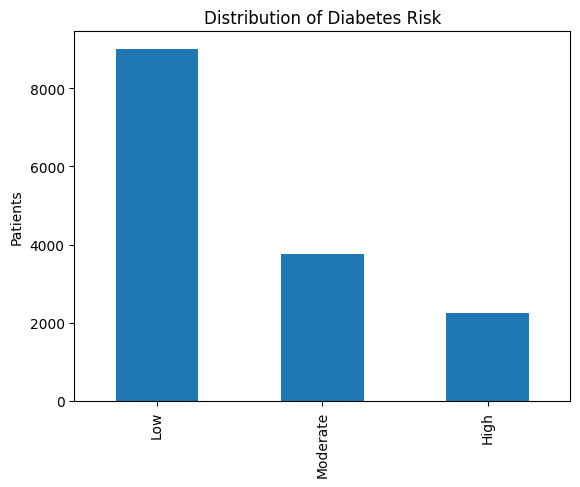

In [141]:
ax = df['diabetes_risk'].value_counts().reindex(['Low','Moderate','High']).plot(kind='bar')
plt.title('Distribution of Diabetes Risk'); plt.xlabel(''); plt.ylabel('Patients')
plt.savefig(output_dir / "diabetes_risk_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [142]:
for c in ['smoking_status','alcohol_consumption','income_bracket']:
    df[c] = df[c].fillna('Unknown')

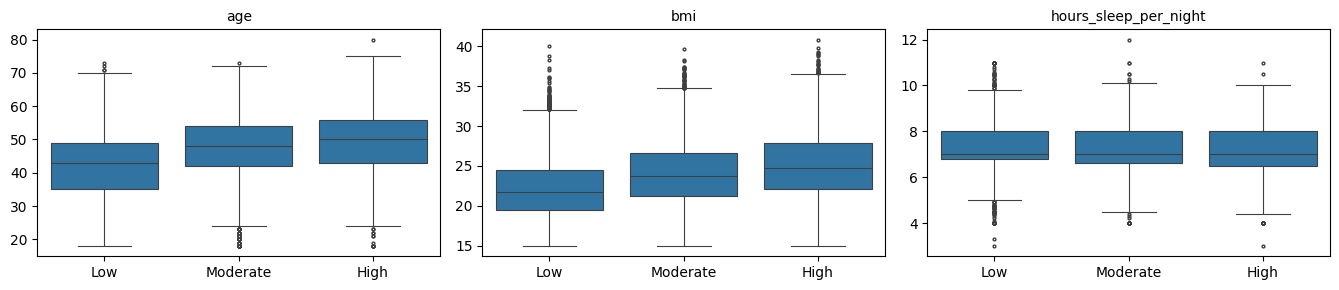

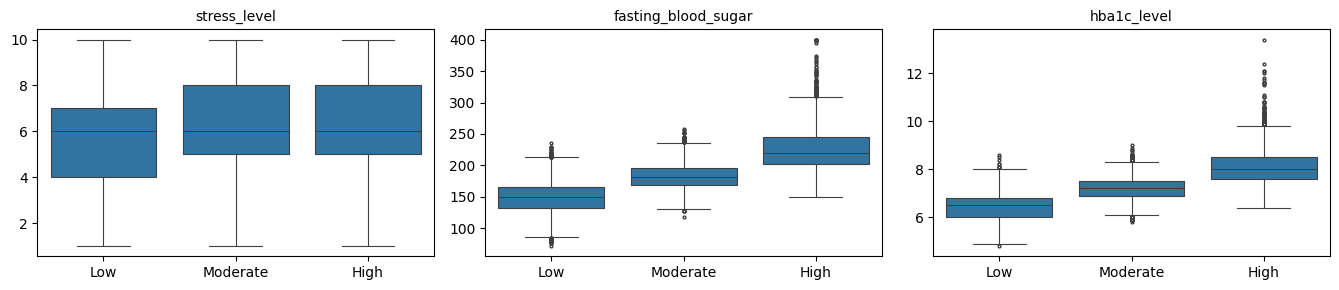

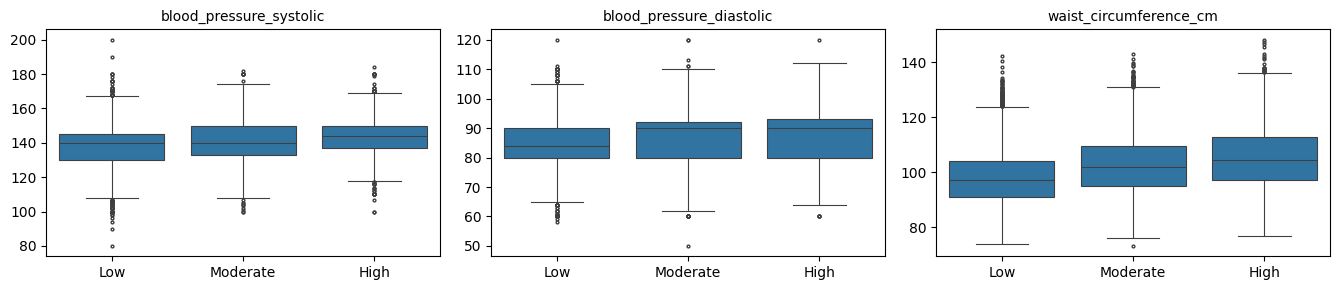

hours_sleep_per_night      -0.043301
stress_level                0.099734
blood_pressure_diastolic    0.166787
blood_pressure_systolic     0.212119
waist_circumference_cm      0.267591
age                         0.286634
bmi                         0.288707
hba1c_level                 0.733878
fasting_blood_sugar         0.738251
dtype: float64


In [143]:
num_cols = df.select_dtypes(include=np.number).columns
order = ['Low', 'Moderate', 'High']

def boxplot_grid(cols, filename, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(4.5*ncols, 3*nrows)
        )
    axes = np.array(axes).ravel()

    for ax, c in zip(axes, cols):
        sns.boxplot(
            data=df, 
            x='diabetes_risk',
            y=c, 
            order=order,
            ax=ax,
            fliersize=2, linewidth=0.8
        )
        ax.set_title(c, fontsize=10)
        ax.set_xlabel('')
        ax.set_ylabel('')

    for ax in axes[len(cols):]:      # esconde eixos vazios
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(output_dir / filename, bbox_inches="tight")
    plt.show()


# 3 em 3 (a última grelha fica com 1 feature)
for i in range(0, len(num_cols), 3):
    boxplot_grid(list(num_cols[i:i+3]), f'boxplots_{i//3 + 1}.png')

y_ord = df['diabetes_risk'].map({'Low':0, 'Moderate':1, 'High':2})
print(df[num_cols].corrwith(y_ord).sort_values())

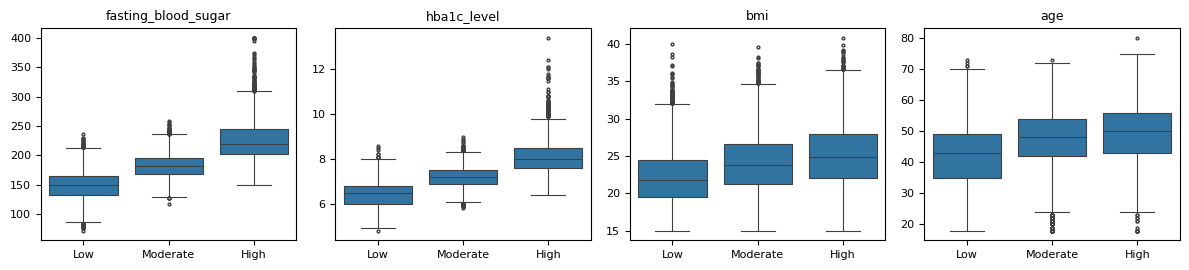

In [144]:
feats = ['fasting_blood_sugar', 'hba1c_level', 'bmi', 'age']
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, f in zip(axes, feats):
    sns.boxplot(data=df, x='diabetes_risk', y=f, order=order, ax=ax, fliersize=2, linewidth=0.8)
    ax.set_title(f, fontsize=9); ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(labelsize=8)
plt.tight_layout()
plt.savefig(output_dir / 'fig_boxplots.png', dpi=200, bbox_inches='tight')
plt.show()

In [145]:
for c in ['gender','family_history_diabetes','physical_activity_level','diet_type',
          'smoking_status','alcohol_consumption','income_bracket']:
    print(pd.crosstab(df[c], df['diabetes_risk'], normalize='index').round(3), '\n')

diabetes_risk   High    Low  Moderate
gender                               
Female         0.152  0.597     0.251
Male           0.147  0.603     0.250
Other          0.183  0.601     0.216 

diabetes_risk             High    Low  Moderate
family_history_diabetes                        
No                       0.125  0.659     0.217
Yes                      0.197  0.491     0.312 

diabetes_risk             High    Low  Moderate
physical_activity_level                        
Active                   0.098  0.701     0.201
Moderate                 0.144  0.591     0.265
Sedentary                0.210  0.505     0.285 

diabetes_risk    High    Low  Moderate
diet_type                             
Non-Vegetarian  0.149  0.601     0.250
Pescatarian     0.146  0.613     0.240
Vegan           0.192  0.559     0.248
Vegetarian      0.150  0.599     0.250 

diabetes_risk    High    Low  Moderate
smoking_status                        
Current         0.145  0.598     0.257
Former          0.1

In [146]:
num_cols = df.select_dtypes(include=np.number).columns
corr = df[num_cols].corr()
print(corr.round(2))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs[abs(pairs) > 0.5].sort_values())

colors = {'Low':'tab:green','Moderate':'tab:orange','High':'tab:red'}


                           age   bmi  hours_sleep_per_night  stress_level  \
age                       1.00  0.21                  -0.01          0.03   
bmi                       0.21  1.00                  -0.03          0.04   
hours_sleep_per_night    -0.01 -0.03                   1.00         -0.38   
stress_level              0.03  0.04                  -0.38          1.00   
fasting_blood_sugar       0.23  0.26                  -0.07          0.16   
hba1c_level               0.21  0.24                  -0.07          0.16   
blood_pressure_systolic   0.48  0.34                  -0.11          0.27   
blood_pressure_diastolic  0.30  0.31                  -0.10          0.27   
waist_circumference_cm    0.19  0.94                  -0.03          0.04   

                          fasting_blood_sugar  hba1c_level  \
age                                      0.23         0.21   
bmi                                      0.26         0.24   
hours_sleep_per_night                   -0.

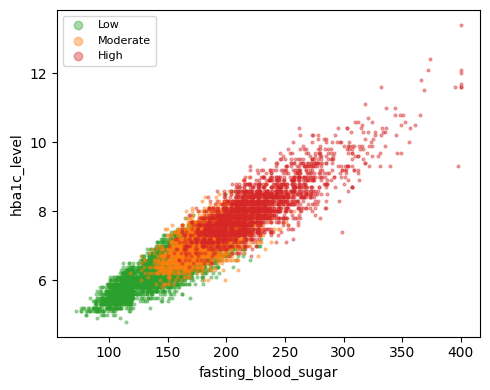

In [147]:
plt.figure(figsize=(5,4))
for k in ['Low','Moderate','High']:
    g = df[df['diabetes_risk'] == k]
    plt.scatter(g['fasting_blood_sugar'], g['hba1c_level'], s=4, alpha=0.4, c=colors[k], label=k)
plt.xlabel('fasting_blood_sugar'); plt.ylabel('hba1c_level'); plt.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig(output_dir / 'fig_scatter.png', dpi=200, bbox_inches='tight')
plt.show()



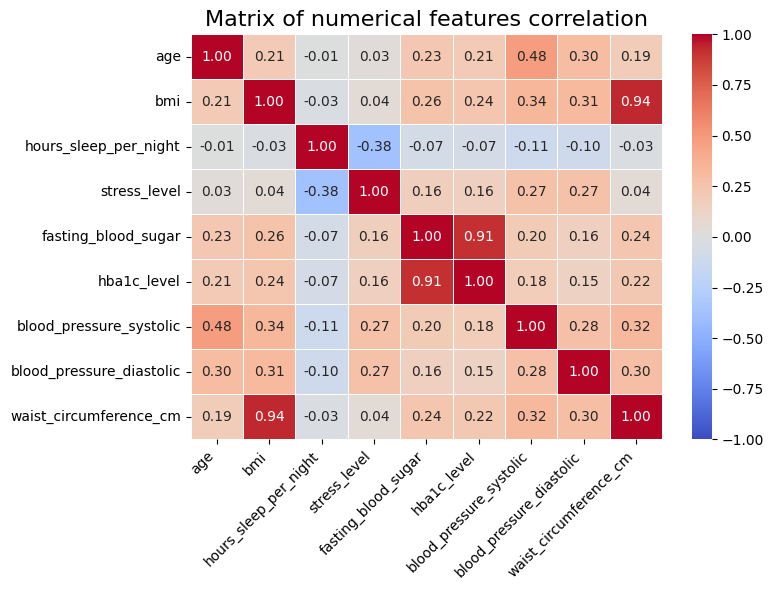

In [148]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title('Matrix of numerical features correlation', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / 'corr_matrix.png', dpi=200, bbox_inches='tight')
plt.show()




In [149]:
cat_cols = df.select_dtypes(exclude=np.number).columns.drop('diabetes_risk')
for c in cat_cols:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[c], df['diabetes_risk']))
    print(f"{c:28s} chi2={chi2:8.1f}  p={p:.4g}")




gender                       chi2=     2.7  p=0.6163
city                         chi2=    53.5  p=0.018
family_history_diabetes      chi2=   402.3  p=4.389e-88
physical_activity_level      chi2=   453.5  p=7.646e-97
diet_type                    chi2=     4.7  p=0.5826
smoking_status               chi2=     6.7  p=0.3448
alcohol_consumption          chi2=     1.7  p=0.9418
income_bracket               chi2=    25.7  p=0.0002496


In [150]:
# Cramers V
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

for c in cat_cols:
    print(f"{c:28s} V={cramers_v(pd.crosstab(df[c], df['diabetes_risk'])):.3f}")

gender                       V=0.009
city                         V=0.042
family_history_diabetes      V=0.164
physical_activity_level      V=0.123
diet_type                    V=0.013
smoking_status               V=0.015
alcohol_consumption          V=0.008
income_bracket               V=0.029


In [151]:
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c:28s} outliers={n} ({100*n/len(df):.2f}%)")
print("diastólica > sistólica:", (df['blood_pressure_diastolic'] > df['blood_pressure_systolic']).sum())
print(df.groupby('diabetes_risk')[['fasting_blood_sugar','hba1c_level','bmi','age']].median())

age                          outliers=3 (0.02%)
bmi                          outliers=153 (1.02%)
hours_sleep_per_night        outliers=360 (2.40%)
stress_level                 outliers=0 (0.00%)
fasting_blood_sugar          outliers=432 (2.88%)
hba1c_level                  outliers=355 (2.37%)
blood_pressure_systolic      outliers=11 (0.07%)
blood_pressure_diastolic     outliers=213 (1.42%)
waist_circumference_cm       outliers=167 (1.11%)
diastólica > sistólica: 1
               fasting_blood_sugar  hba1c_level   bmi   age
diabetes_risk                                              
High                         220.0          8.0  24.8  50.0
Low                          150.0          6.5  21.8  43.0
Moderate                     182.0          7.2  23.8  48.0


In [152]:
X = df.drop(columns=['diabetes_risk'])
y = df['diabetes_risk']

def make_split(X, y, seed, test_size=0.20, val_size=0.20):
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=val_size/(1-test_size), stratify=y_tmp, random_state=seed)
    return X_train, X_val, X_test, y_train, y_val, y_test

SEEDS = list(range(10))
Xtr, Xva, Xte, ytr, yva, yte = make_split(X, y, seed=SEEDS[0])
for name, yy in [('train', ytr), ('val', yva), ('test', yte)]:
    print(name, len(yy), yy.value_counts(normalize=True).round(3).to_dict())

train 9000 {'Low': 0.6, 'Moderate': 0.25, 'High': 0.15}
val 3000 {'Low': 0.6, 'Moderate': 0.25, 'High': 0.15}
test 3000 {'Low': 0.6, 'Moderate': 0.25, 'High': 0.15}


In [153]:
num_cols = ['age','bmi','hours_sleep_per_night','stress_level','fasting_blood_sugar',
            'hba1c_level','blood_pressure_systolic','blood_pressure_diastolic',
            'waist_circumference_cm']
ord_cols = ['physical_activity_level']
bin_cols = ['family_history_diabetes']
nom_cols = ['gender','city','diet_type','smoking_status','alcohol_consumption','income_bracket']

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('ord', Pipeline([('enc', OrdinalEncoder(categories=[['Sedentary','Moderate','Active']])),
                      ('sc', StandardScaler())]), ord_cols),
    ('bin', Pipeline([('enc', OrdinalEncoder(categories=[['No','Yes']])),
                      ('sc', StandardScaler())]), bin_cols),
    ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nom_cols),
])

Xtr_p = preprocess.fit_transform(Xtr)      # ajusta SÓ no treino
Xva_p = preprocess.transform(Xva)
Xte_p = preprocess.transform(Xte)

names = preprocess.get_feature_names_out()
print(Xtr_p.shape, Xva_p.shape, Xte_p.shape)
print(list(names))
print(Xtr_p[:, :9].mean(axis=0).round(2), Xtr_p[:, :9].std(axis=0).round(2))

(9000, 48) (3000, 48) (3000, 48)
['num__age', 'num__bmi', 'num__hours_sleep_per_night', 'num__stress_level', 'num__fasting_blood_sugar', 'num__hba1c_level', 'num__blood_pressure_systolic', 'num__blood_pressure_diastolic', 'num__waist_circumference_cm', 'ord__physical_activity_level', 'bin__family_history_diabetes', 'nom__gender_Female', 'nom__gender_Male', 'nom__gender_Other', 'nom__city_Ahmedabad', 'nom__city_Bengaluru', 'nom__city_Bhopal', 'nom__city_Chennai', 'nom__city_Delhi', 'nom__city_Hyderabad', 'nom__city_Indore', 'nom__city_Jaipur', 'nom__city_Kanpur', 'nom__city_Kolkata', 'nom__city_Lucknow', 'nom__city_Mumbai', 'nom__city_Nagpur', 'nom__city_Patna', 'nom__city_Pune', 'nom__city_Surat', 'nom__city_Thane', 'nom__city_Visakhapatnam', 'nom__diet_type_Non-Vegetarian', 'nom__diet_type_Pescatarian', 'nom__diet_type_Vegan', 'nom__diet_type_Vegetarian', 'nom__smoking_status_Current', 'nom__smoking_status_Former', 'nom__smoking_status_Never', 'nom__smoking_status_Unknown', 'nom__alco

In [154]:
feat_names = [n.split('__', 1)[1] for n in names[:11]]
Xf = pd.DataFrame(Xtr_p[:, :11], columns=feat_names)
classes = ['Low', 'Moderate', 'High']

rows = []
for f in feat_names:
    groups = [Xf.loc[ytr.values == k, f] for k in classes]
    H, p = kruskal(*groups)
    aucs = {k: roc_auc_score((ytr.values == k).astype(int), Xf[f]) for k in classes}
    # AUC < 0.5 = feature a funcionar ao contrário: usar max(auc, 1-auc)
    auc_macro = np.mean([max(a, 1 - a) for a in aucs.values()])
    rows.append({'feature': f, 'H': H, 'p': p, 'AUC_macro': auc_macro,
                 **{f'AUC_{k}': v for k, v in aucs.items()}})

rank = pd.DataFrame(rows).sort_values('H', ascending=False).round(3)
print(rank.to_string(index=False))

                 feature        H     p  AUC_macro  AUC_Low  AUC_Moderate  AUC_High
     fasting_blood_sugar 4888.647 0.000      0.862    0.088         0.721     0.951
             hba1c_level 4733.907 0.000      0.855    0.095         0.714     0.946
                     age  749.317 0.000      0.644    0.332         0.612     0.651
                     bmi  701.331 0.000      0.638    0.341         0.595     0.660
  waist_circumference_cm  595.257 0.000      0.627    0.354         0.586     0.649
 blood_pressure_systolic  392.660 0.000      0.603    0.382         0.567     0.622
 physical_activity_level  279.828 0.000      0.581    0.593         0.451     0.397
blood_pressure_diastolic  275.954 0.000      0.586    0.400         0.562     0.596
 family_history_diabetes  254.897 0.000      0.569    0.418         0.561     0.564
            stress_level  100.343 0.000      0.552    0.439         0.542     0.553
   hours_sleep_per_night   14.291 0.001      0.520    0.523         0.485   

In [155]:
order_feats = rank['feature'].tolist()           # ordenadas por H
idx = {n: i for i, n in enumerate(feat_names)}
res = []
for k in range(1, len(order_feats) + 1):
    cols = [idx[f] for f in order_feats[:k]]
    lda = LinearDiscriminantAnalysis().fit(Xtr_p[:, cols], ytr)
    res.append((k, order_feats[k-1],
                balanced_accuracy_score(ytr, lda.predict(Xtr_p[:, cols])),
                balanced_accuracy_score(yva, lda.predict(Xva_p[:, cols]))))
print(pd.DataFrame(res, columns=['k', 'added', 'BACC_train', 'BACC_val']).round(3))

     k                     added  BACC_train  BACC_val
0    1       fasting_blood_sugar       0.654     0.623
1    2               hba1c_level       0.674     0.652
2    3                       age       0.700     0.677
3    4                       bmi       0.707     0.689
4    5    waist_circumference_cm       0.708     0.688
5    6   blood_pressure_systolic       0.708     0.689
6    7   physical_activity_level       0.708     0.688
7    8  blood_pressure_diastolic       0.708     0.686
8    9   family_history_diabetes       0.711     0.692
9   10              stress_level       0.707     0.690
10  11     hours_sleep_per_night       0.707     0.690


In [156]:
corr_tr = pd.DataFrame(Xtr_p[:, :9], columns=feat_names[:9]).corr()
p = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool)).stack()
print(p[abs(p) > 0.5].sort_values().round(3))

fasting_blood_sugar  hba1c_level               0.916
bmi                  waist_circumference_cm    0.936
dtype: float64


In [157]:
# χ² e V de Cramér só no treino (inclui as 2 relevantes para comparar)
cats = ['family_history_diabetes', 'physical_activity_level', 'gender', 'city',
        'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket']
for c in cats:
    ct = pd.crosstab(Xtr[c], ytr)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{c:26s} chi2={chi2:7.1f}  p={p:.3g}  V={v:.3f}")

# Conjuntos de features selecionadas (por nome das colunas já preprocessadas)
S4 = ['num__fasting_blood_sugar', 'num__hba1c_level', 'num__age', 'num__bmi']
S5 = S4 + ['bin__family_history_diabetes']
names_list = list(names)
idx_S4 = [names_list.index(n) for n in S4]
idx_S5 = [names_list.index(n) for n in S5]
print(idx_S4, idx_S5)

family_history_diabetes    chi2=  254.9  p=4.4e-56  V=0.168
physical_activity_level    chi2=  290.0  p=1.53e-61  V=0.127
gender                     chi2=    0.8  p=0.942  V=0.007
city                       chi2=   39.0  p=0.255  V=0.047
diet_type                  chi2=    6.2  p=0.396  V=0.019
smoking_status             chi2=    5.2  p=0.517  V=0.017
alcohol_consumption        chi2=    3.4  p=0.757  V=0.014
income_bracket             chi2=   12.5  p=0.0523  V=0.026
[4, 5, 0, 1] [4, 5, 0, 1, 10]


 PC  eigenvalue    R_%  R_cum_%
  1       3.293 56.326   56.326
  2       1.622 13.662   69.988
  3       1.432 10.652   80.640
  4       1.121  6.530   87.170
  5       0.944  4.633   91.803
  6       0.761  3.010   94.813
  7       0.663  2.281   97.094
  8       0.631  2.068   99.162
  9       0.388  0.781   99.943
 10       0.084  0.036   99.980
 11       0.063  0.020  100.000
Kaiser (λ > 1): 4 componentes


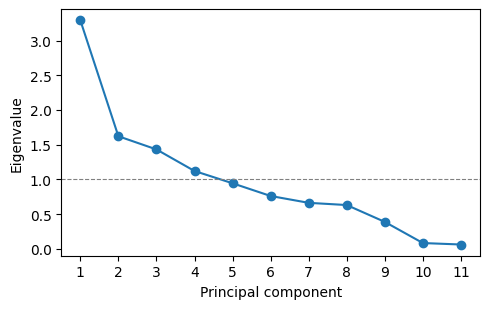

                           PC1   PC2   PC3   PC4
age                       0.27  0.01  0.12  0.68
bmi                       0.43 -0.36 -0.17 -0.22
hours_sleep_per_night    -0.09 -0.17 -0.54  0.38
stress_level              0.17  0.22  0.56 -0.26
fasting_blood_sugar       0.34  0.52 -0.26 -0.04
hba1c_level               0.33  0.52 -0.27 -0.05
blood_pressure_systolic   0.33 -0.04  0.28  0.39
blood_pressure_diastolic  0.29 -0.07  0.27  0.16
waist_circumference_cm    0.42 -0.37 -0.17 -0.23
physical_activity_level  -0.32  0.25  0.04  0.17
family_history_diabetes   0.05  0.22 -0.17 -0.08
    n_components  BACC_train  BACC_val
0              1       0.513     0.504
1              2       0.650     0.634
2              3       0.701     0.667
3              4       0.703     0.671
4              5       0.708     0.685
5              6       0.708     0.685
6              7       0.710     0.682
7              8       0.707     0.686
8              9       0.708     0.691
9             10      

In [158]:
X11_tr, X11_va, X11_te = Xtr_p[:, :11], Xva_p[:, :11], Xte_p[:, :11]

pca = PCA().fit(X11_tr)                          # só no treino
eig = pca.explained_variance_                    # valores próprios (λ)

R_comp = 100 * eig**2 / np.sum(eig**2)           # contribuição de cada PC (fórmula dos slides)
R_cum  = np.cumsum(R_comp)                       # R(%) com as M primeiras PCs

tab = pd.DataFrame({'PC': range(1, 12), 'eigenvalue': eig,
                    'R_%': R_comp, 'R_cum_%': R_cum}).round(3)
print(tab.to_string(index=False))
print("Kaiser (λ > 1):", (eig > 1).sum(), "componentes")

# Scree plot
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(range(1, 12), eig, 'o-')
ax.axhline(1, ls='--', c='gray', lw=0.8)
ax.set_xlabel('Principal component'); ax.set_ylabel('Eigenvalue')
ax.set_xticks(range(1, 12))
plt.tight_layout()
plt.savefig(output_dir / 'fig_scree.png', dpi=200, bbox_inches='tight')
plt.show()

# O que cada componente representa
loadings = pd.DataFrame(pca.components_[:4].T, index=feat_names,
                        columns=[f'PC{i}' for i in range(1, 5)]).round(2)
print(loadings)

# Quantas componentes? BACC de validação (Fisher LDA) vs número de componentes
Ztr, Zva = pca.transform(X11_tr), pca.transform(X11_va)
res = []
for m in range(1, 12):
    lda = LinearDiscriminantAnalysis().fit(Ztr[:, :m], ytr)
    res.append((m, balanced_accuracy_score(ytr, lda.predict(Ztr[:, :m])),
                   balanced_accuracy_score(yva, lda.predict(Zva[:, :m]))))
print(pd.DataFrame(res, columns=['n_components', 'BACC_train', 'BACC_val']).round(3))

Variância entre-classes por discriminante: [0.988 0.012]
                           LD1   LD2
age                      -0.22  0.73
bmi                      -0.17  0.59
hours_sleep_per_night    -0.01  0.04
stress_level              0.03  0.36
fasting_blood_sugar      -0.72 -0.45
hba1c_level              -0.75 -0.09
blood_pressure_systolic   0.02 -0.20
blood_pressure_diastolic -0.01  0.04
waist_circumference_cm   -0.01 -0.13
physical_activity_level  -0.02  0.12
family_history_diabetes  -0.10  0.57
BACC val, MDC em PCA(2): 0.662
BACC val, MDC em LDA(2): 0.739


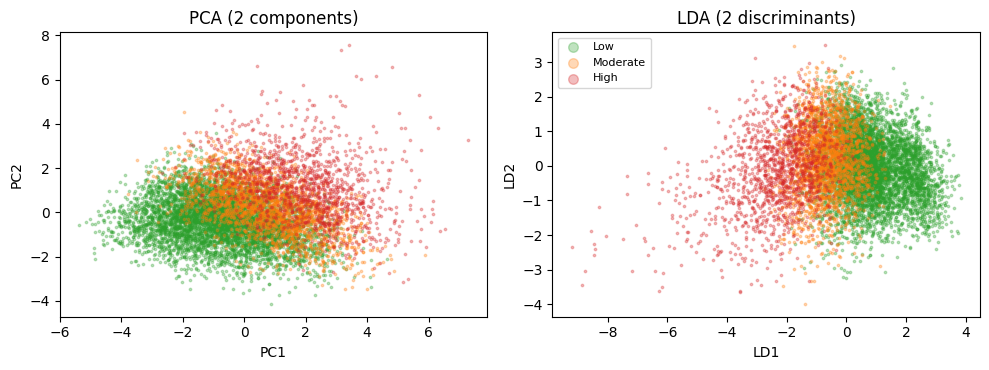

In [159]:
# LDA: 11 features -> 2 discriminantes (ajustada só no treino)
lda = LinearDiscriminantAnalysis(solver='svd', n_components=2).fit(X11_tr, ytr)
Ltr, Lva = lda.transform(X11_tr), lda.transform(X11_va)

print("Variância entre-classes por discriminante:", lda.explained_variance_ratio_.round(3))
print(pd.DataFrame(lda.scalings_[:, :2], index=feat_names, columns=['LD1', 'LD2']).round(2))

# MDC (distância mínima aos centróides) em PCA(2) vs LDA(2); Ztr/Zva vêm da célula da PCA
mdc_pca = NearestCentroid().fit(Ztr[:, :2], ytr)
mdc_lda = NearestCentroid().fit(Ltr, ytr)
print("BACC val, MDC em PCA(2):", round(balanced_accuracy_score(yva, mdc_pca.predict(Zva[:, :2])), 3))
print("BACC val, MDC em LDA(2):", round(balanced_accuracy_score(yva, mdc_lda.predict(Lva)), 3))

# Figura: PCA(2) vs LDA(2) (treino)
colors = {'Low': 'tab:green', 'Moderate': 'tab:orange', 'High': 'tab:red'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, Z, lab in [(axes[0], Ztr[:, :2], ('PC1', 'PC2')), (axes[1], Ltr, ('LD1', 'LD2'))]:
    for k in ['Low', 'Moderate', 'High']:
        m = (ytr.values == k)
        ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.3, c=colors[k], label=k)
    ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1])
axes[0].set_title('PCA (2 components)'); axes[1].set_title('LDA (2 discriminants)')
axes[1].legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.savefig(output_dir / 'fig_pca_lda.png', dpi=200, bbox_inches='tight')
plt.show()

In [160]:
unif = [1/3, 1/3, 1/3]
def bacc_val(Atr, Ava):
    m = LinearDiscriminantAnalysis(priors=unif).fit(Atr, ytr)
    return balanced_accuracy_score(yva, m.predict(Ava))

# curva de adição de features (ordem do H)
res = []
for k in range(1, 12):
    cols = [idx[f] for f in order_feats[:k]]
    res.append((k, order_feats[k-1], bacc_val(Xtr_p[:, cols], Xva_p[:, cols])))
print(pd.DataFrame(res, columns=['k', 'added', 'BACC_val']).round(3))

# curva da PCA
res = [(m, bacc_val(Ztr[:, :m], Zva[:, :m])) for m in range(1, 12)]
print(pd.DataFrame(res, columns=['n_components', 'BACC_val']).round(3))

print('S4', round(bacc_val(Xtr_p[:, idx_S4], Xva_p[:, idx_S4]), 3))
print('S5', round(bacc_val(Xtr_p[:, idx_S5], Xva_p[:, idx_S5]), 3))

     k                     added  BACC_val
0    1       fasting_blood_sugar     0.694
1    2               hba1c_level     0.709
2    3                       age     0.729
3    4                       bmi     0.740
4    5    waist_circumference_cm     0.740
5    6   blood_pressure_systolic     0.738
6    7   physical_activity_level     0.741
7    8  blood_pressure_diastolic     0.737
8    9   family_history_diabetes     0.739
9   10              stress_level     0.739
10  11     hours_sleep_per_night     0.739
    n_components  BACC_val
0              1     0.561
1              2     0.682
2              3     0.726
3              4     0.728
4              5     0.741
5              6     0.742
6              7     0.739
7              8     0.739
8              9     0.736
9             10     0.739
10            11     0.739
S4 0.74
S5 0.743
